Import Library

In [2]:
import os
import time
import copy
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import datasets, models, transforms
from torchvision.models import ResNet18_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
Device: cuda
GPU: Tesla T4


Reproducibility

In [ ]:
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

print("Random seed:", SEED)

Random seed: 42


Download Dataset

In [ ]:
DATA_ROOT = "./data"

trainval_dataset = datasets.OxfordIIITPet(
    root=DATA_ROOT,
    split="trainval",
    target_types="category",
    download=True
)

official_test_dataset = datasets.OxfordIIITPet(
    root=DATA_ROOT,
    split="test",
    target_types="category",
    download=True
)

full_dataset = ConcatDataset([trainval_dataset, official_test_dataset])
class_names = trainval_dataset.classes

print("Jumlah data trainval:", len(trainval_dataset))
print("Jumlah data official test:", len(official_test_dataset))
print("Jumlah data gabungan:", len(full_dataset))
print("Jumlah kelas:", len(class_names))
print("Contoh kelas:", class_names[:10])


100%|██████████| 792M/792M [00:23<00:00, 33.2MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 14.4MB/s]


Jumlah data trainval: 3680
Jumlah data official test: 3669
Jumlah data gabungan: 7349
Jumlah kelas: 37
Contoh kelas: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair']


Selected Class (10)

In [ ]:
selected_breeds = [
    "Abyssinian",
    "Bengal",
    "Birman",
    "British Shorthair",
    "Persian",
    "american bulldog",
    "american pit bull terrier",
    "basset hound",
    "beagle",
    "boxer"
]

#normalisasi nama
class_to_idx_original = {
    name.lower(): idx for idx, name in enumerate(class_names)
}

selected_indices_original = []

for breed in selected_breeds:
    key = breed.lower()
    if key not in class_to_idx_original:
        raise ValueError(
            f"Kelas '{breed}' tidak ditemukan. "
            f"Silakan cek class_names."
        )
    selected_indices_original.append(class_to_idx_original[key])

print("Kelas yang digunakan:")
for i, breed in enumerate(selected_breeds):
    print(i, "->", breed)

Kelas yang digunakan:
0 -> Abyssinian
1 -> Bengal
2 -> Birman
3 -> British Shorthair
4 -> Persian
5 -> american bulldog
6 -> american pit bull terrier
7 -> basset hound
8 -> beagle
9 -> boxer


Subset 10 Kelas

In [ ]:
all_targets = np.concatenate([
    np.asarray(trainval_dataset._labels),
    np.asarray(official_test_dataset._labels)
])

selected_mask = np.isin(all_targets, selected_indices_original)
selected_positions = np.where(selected_mask)[0]

selected_original_targets = all_targets[selected_positions]

original_to_new = {
    original_idx: new_idx
    for new_idx, original_idx in enumerate(selected_indices_original)
}

selected_targets = np.array([
    original_to_new[int(label)]
    for label in selected_original_targets
])

print("Total data 10 kelas:", len(selected_positions))
print("Distribusi kelas:")
print(Counter(selected_targets))


Total data 10 kelas: 1997
Distribusi kelas:
Counter({np.int64(5): 200, np.int64(6): 200, np.int64(7): 200, np.int64(8): 200, np.int64(1): 200, np.int64(2): 200, np.int64(3): 200, np.int64(4): 200, np.int64(9): 199, np.int64(0): 198})


Stratified Split 70/15/15

In [ ]:
train_pos, temp_pos = train_test_split(
    selected_positions,
    test_size=0.30,
    random_state=SEED,
    stratify=selected_targets
)

temp_targets = all_targets[temp_pos]
temp_targets_new = np.array([
    original_to_new[int(label)]
    for label in temp_targets
])

val_pos, test_pos = train_test_split(
    temp_pos,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_targets_new
)

print("Train:", len(train_pos))
print("Validation:", len(val_pos))
print("Test:", len(test_pos))
print("Total:", len(train_pos) + len(val_pos) + len(test_pos))

Train: 1397
Validation: 300
Test: 300
Total: 1997


Check Class Distribution

In [8]:
def get_new_labels(positions):
    return np.array([
        original_to_new[int(all_targets[p])]
        for p in positions
    ])

for name, positions in [
    ("Train", train_pos),
    ("Validation", val_pos),
    ("Test", test_pos)
]:
    labels = get_new_labels(positions)
    print(f"\n{name}")
    print(Counter(labels))


Train
Counter({np.int64(3): 140, np.int64(5): 140, np.int64(6): 140, np.int64(1): 140, np.int64(2): 140, np.int64(4): 140, np.int64(7): 140, np.int64(8): 140, np.int64(9): 139, np.int64(0): 138})

Validation
Counter({np.int64(7): 30, np.int64(8): 30, np.int64(2): 30, np.int64(9): 30, np.int64(0): 30, np.int64(5): 30, np.int64(4): 30, np.int64(6): 30, np.int64(3): 30, np.int64(1): 30})

Test
Counter({np.int64(3): 30, np.int64(5): 30, np.int64(0): 30, np.int64(8): 30, np.int64(6): 30, np.int64(1): 30, np.int64(4): 30, np.int64(2): 30, np.int64(9): 30, np.int64(7): 30})


Transforms

In [9]:
weights = ResNet18_Weights.IMAGENET1K_V1

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform_no_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

train_transform_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

Dataset Wrapper

In [10]:
class OxfordPetSubset(Dataset):
    def __init__(self, base_dataset, positions, transform, label_mapping):
        self.base_dataset = base_dataset
        self.positions = list(positions)
        self.transform = transform
        self.label_mapping = label_mapping

    def __len__(self):
        return len(self.positions)

    def __getitem__(self, idx):
        position = self.positions[idx]

        image, original_label = self.base_dataset[position]

        new_label = self.label_mapping[int(original_label)]

        if self.transform is not None:
            image = self.transform(image)

        return image, new_label


def create_dataloaders(train_transform):
    train_dataset = OxfordPetSubset(
        full_dataset,
        train_pos,
        train_transform,
        original_to_new
    )

    val_dataset = OxfordPetSubset(
        full_dataset,
        val_pos,
        eval_transform,
        original_to_new
    )

    test_dataset = OxfordPetSubset(
        full_dataset,
        test_pos,
        eval_transform,
        original_to_new
    )

    train_generator = torch.Generator()
    train_generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=train_generator,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=32,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=32,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    return train_dataset, val_dataset, test_dataset, train_loader, val_loader, test_loader

Cek 1 Batch

In [11]:
_, _, _, train_loader_check, val_loader_check, test_loader_check = create_dataloaders(
    train_transform_aug
)

images, labels = next(iter(train_loader_check))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Label contoh:", labels[:10].tolist())

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Label contoh: [5, 5, 4, 8, 7, 1, 3, 4, 9, 5]


Model ResNet-18 Untuk B1, B2, B3

In [ ]:
NUM_CLASSES = 10

def build_resnet18(experiment):
    if experiment == "B1":
        model = models.resnet18(weights=None)

    elif experiment in ["B2", "B3"]:
        model = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

    else:
        raise ValueError("Experiment harus B1, B2, atau B3.")

    #ganti classifier
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

    #freeze semuanya dulu
    if experiment == "B1":
        for param in model.parameters():
            param.requires_grad = True

    elif experiment == "B2":
        for param in model.parameters():
            param.requires_grad = False

        for param in model.fc.parameters():
            param.requires_grad = True

    elif experiment == "B3":
        for param in model.parameters():
            param.requires_grad = False

        for param in model.layer4.parameters():
            param.requires_grad = True

        for param in model.fc.parameters():
            param.requires_grad = True

    return model.to(device)


def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )
    return total, trainable


for exp in ["B1", "B2", "B3"]:
    model = build_resnet18(exp)
    total, trainable = count_parameters(model)
    print(f"{exp}: {trainable:,} / {total:,} trainable")

B1: 11,181,642 / 11,181,642 trainable
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 160MB/s]


B2: 5,130 / 11,181,642 trainable
B3: 8,398,858 / 11,181,642 trainable


Optimizer

In [13]:
def build_optimizer(model, experiment):
    if experiment == "B1":
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=1e-3,
            weight_decay=1e-2
        )

    elif experiment == "B2":
        optimizer = torch.optim.AdamW(
            [
                {"params": model.fc.parameters(), "lr": 1e-3}
            ],
            weight_decay=1e-2
        )

    elif experiment == "B3":
        optimizer = torch.optim.AdamW(
            [
                {"params": model.layer4.parameters(), "lr": 1e-4},
                {"params": model.fc.parameters(), "lr": 1e-3}
            ],
            weight_decay=1e-2
        )

    else:
        raise ValueError("Experiment tidak dikenali.")

    return optimizer

Training and Validations

In [14]:
criterion = nn.CrossEntropyLoss()

def train_one_epoch(model, loader, optimizer):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc


@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    running_loss = 0.0
    all_labels = []
    all_predictions = []

    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)
        total += labels.size(0)

        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    loss = running_loss / total
    accuracy = accuracy_score(all_labels, all_predictions)

    return loss, accuracy, all_labels, all_predictions

Early Stopping Training

In [ ]:
def train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    experiment_name,
    max_epochs=20,
    patience=4
):
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0
    stopped_epoch = 0

    start_time = time.time()

    for epoch in range(1, max_epochs + 1):
        train_loss, train_acc = train_one_epoch(
            model, train_loader, optimizer
        )

        val_loss, val_acc, _, _ = evaluate(model, val_loader)

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        print(
            f"[{experiment_name}] "
            f"Epoch {epoch:02d}/{max_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        stopped_epoch = epoch

        if epochs_without_improvement >= patience:
            print(
                f"Early stopping pada epoch {stopped_epoch} "
                f"(patience={patience})."
            )
            break

    training_time = time.time() - start_time

    model.load_state_dict(best_state)
    best_epoch = int(np.argmin(history["val_loss"])) + 1

    return (
        model, history, training_time, stopped_epoch,
        best_epoch, best_val_loss
    )


Test Evaluation and Result Logger

In [16]:
def evaluate_test(model, test_loader):
    loss, accuracy, y_true, y_pred = evaluate(model, test_loader)

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro"
    )

    return {
        "test_loss": loss,
        "test_accuracy": accuracy,
        "test_macro_f1": macro_f1,
        "y_true": y_true,
        "y_pred": y_pred
    }


results = []
histories = {}
trained_models = {}
test_outputs = {}

# B1 (Baseline from scratch)

Di inisialisasi random (weights=None) dan seluruh parameter dapat diupdate selama training

In [17]:
set_seed(SEED)

train_dataset, val_dataset, test_dataset, train_loader, val_loader, test_loader = (
    create_dataloaders(train_transform_no_aug)
)

model_b1 = build_resnet18("B1")
optimizer_b1 = build_optimizer(model_b1, "B1")

total_params, trainable_params = count_parameters(model_b1)

model_b1, history_b1, time_b1, stopped_epoch_b1, best_epoch_b1, best_val_loss_b1 = train_model(
    model_b1,
    train_loader,
    val_loader,
    optimizer_b1,
    experiment_name="B1",
    max_epochs=20,
    patience=4
)

test_b1 = evaluate_test(model_b1, test_loader)

best_val_acc_b1 = history_b1["val_accuracy"][best_epoch_b1 - 1]

histories["B1"] = history_b1
trained_models["B1"] = model_b1
test_outputs["B1"] = test_b1

results.append({
    "experiment": "B1",
    "architecture": "ResNet-18",
    "strategy": "From Scratch",
    "trainable_parameters": trainable_params,
    "learning_rate": "1e-3",
    "converged_epoch": stopped_epoch_b1,
    "best_epoch": best_epoch_b1,
    "training_time_seconds": time_b1,
    "best_val_loss": best_val_loss_b1,
    "val_accuracy_at_best": best_val_acc_b1,
    "test_accuracy": test_b1["test_accuracy"],
    "test_macro_f1": test_b1["test_macro_f1"]
})


[B1] Epoch 01/20 | Train Loss: 2.2861 | Train Acc: 0.2097 | Val Loss: 2.2588 | Val Acc: 0.2333
[B1] Epoch 02/20 | Train Loss: 1.9112 | Train Acc: 0.3207 | Val Loss: 2.0277 | Val Acc: 0.2500
[B1] Epoch 03/20 | Train Loss: 1.7865 | Train Acc: 0.3722 | Val Loss: 1.7282 | Val Acc: 0.4100
[B1] Epoch 04/20 | Train Loss: 1.6690 | Train Acc: 0.4023 | Val Loss: 1.9470 | Val Acc: 0.3167
[B1] Epoch 05/20 | Train Loss: 1.5626 | Train Acc: 0.4424 | Val Loss: 1.9507 | Val Acc: 0.3300
[B1] Epoch 06/20 | Train Loss: 1.5098 | Train Acc: 0.4624 | Val Loss: 1.8553 | Val Acc: 0.3700
[B1] Epoch 07/20 | Train Loss: 1.3148 | Train Acc: 0.5326 | Val Loss: 1.8250 | Val Acc: 0.4167
Early stopping pada epoch 7 (patience=4).


In [18]:
print("\n=-= B1 RESULTS =-=")
print(f"Early stopping epoch: {stopped_epoch_b1}")
print(f"Best epoch: {best_epoch_b1}")
print(f"Best validation loss: {best_val_loss_b1:.4f}")
print(f"Validation accuracy at best: {best_val_acc_b1:.4f} ({best_val_acc_b1 * 100:.2f}%)")
print(f"Test accuracy: {test_b1['test_accuracy']:.4f}")
print(f"Test Macro F1: {test_b1['test_macro_f1']:.4f}")


=-= B1 RESULTS =-=
Early stopping epoch: 7
Best epoch: 3
Best validation loss: 1.7282
Validation accuracy at best: 0.4100 (41.00%)
Test accuracy: 0.3767
Test Macro F1: 0.3380


# B2 (Feature Extraction)

Model menggunakan bobot ImageNet pretrained dan seluruh BackBone dibekukan dan hanya classifier fc yang dilatih

In [19]:
set_seed(SEED)

train_dataset, val_dataset, test_dataset, train_loader, val_loader, test_loader = (
    create_dataloaders(train_transform_no_aug)
)

model_b2 = build_resnet18("B2")
optimizer_b2 = build_optimizer(model_b2, "B2")

total_params, trainable_params = count_parameters(model_b2)

print(f"Trainable parameters B2: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")

model_b2, history_b2, time_b2, stopped_epoch_b2, best_epoch_b2, best_val_loss_b2 = train_model(
    model_b2,
    train_loader,
    val_loader,
    optimizer_b2,
    experiment_name="B2",
    max_epochs=20,
    patience=4
)

test_b2 = evaluate_test(model_b2, test_loader)

best_val_acc_b2 = history_b2["val_accuracy"][best_epoch_b2 - 1]

histories["B2"] = history_b2
trained_models["B2"] = model_b2
test_outputs["B2"] = test_b2

results.append({
    "experiment": "B2",
    "architecture": "ResNet-18",
    "strategy": "Feature Extraction",
    "trainable_parameters": trainable_params,
    "learning_rate": "1e-3 (fc)",
    "converged_epoch": stopped_epoch_b2,
    "best_epoch": best_epoch_b2,
    "training_time_seconds": time_b2,
    "best_val_loss": best_val_loss_b2,
    "val_accuracy_at_best": best_val_acc_b2,
    "test_accuracy": test_b2["test_accuracy"],
    "test_macro_f1": test_b2["test_macro_f1"]
})


Trainable parameters B2: 5,130
Total parameters: 11,181,642
[B2] Epoch 01/20 | Train Loss: 1.4209 | Train Acc: 0.5798 | Val Loss: 0.7770 | Val Acc: 0.8000
[B2] Epoch 02/20 | Train Loss: 0.6102 | Train Acc: 0.8626 | Val Loss: 0.4690 | Val Acc: 0.8867
[B2] Epoch 03/20 | Train Loss: 0.4325 | Train Acc: 0.8948 | Val Loss: 0.3765 | Val Acc: 0.9000
[B2] Epoch 04/20 | Train Loss: 0.3630 | Train Acc: 0.9098 | Val Loss: 0.3410 | Val Acc: 0.9133
[B2] Epoch 05/20 | Train Loss: 0.2943 | Train Acc: 0.9327 | Val Loss: 0.3105 | Val Acc: 0.9067
[B2] Epoch 06/20 | Train Loss: 0.2803 | Train Acc: 0.9263 | Val Loss: 0.2812 | Val Acc: 0.9367
[B2] Epoch 07/20 | Train Loss: 0.2541 | Train Acc: 0.9313 | Val Loss: 0.2586 | Val Acc: 0.9167
[B2] Epoch 08/20 | Train Loss: 0.2274 | Train Acc: 0.9449 | Val Loss: 0.2519 | Val Acc: 0.9267
[B2] Epoch 09/20 | Train Loss: 0.2137 | Train Acc: 0.9427 | Val Loss: 0.2462 | Val Acc: 0.9300
[B2] Epoch 10/20 | Train Loss: 0.2042 | Train Acc: 0.9435 | Val Loss: 0.2380 | Val Ac

In [20]:
print("\n=-= B2 RESULTS =-=")
print(f"Early stopping epoch: {stopped_epoch_b2}")
print(f"Best epoch: {best_epoch_b2}")
print(f"Best validation loss: {best_val_loss_b2:.4f}")
print(f"Validation accuracy at best: {best_val_acc_b2:.4f} ({best_val_acc_b2 * 100:.2f}%)")
print(f"Test accuracy: {test_b2['test_accuracy']:.4f}")
print(f"Test Macro F1: {test_b2['test_macro_f1']:.4f}")


=-= B2 RESULTS =-=
Early stopping epoch: 20
Best epoch: 17
Best validation loss: 0.2164
Validation accuracy at best: 0.9233 (92.33%)
Test accuracy: 0.9400
Test Macro F1: 0.9402


# B3 (Progressive Fine Tuning)

In [21]:
set_seed(SEED)

train_dataset, val_dataset, test_dataset, train_loader, val_loader, test_loader = (
    create_dataloaders(train_transform_no_aug)
)

model_b3 = build_resnet18("B3")
optimizer_b3 = build_optimizer(model_b3, "B3")

total_params, trainable_params = count_parameters(model_b3)

print(f"Trainable parameters B3: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")

model_b3, history_b3, time_b3, stopped_epoch_b3, best_epoch_b3, best_val_loss_b3 = train_model(
    model_b3,
    train_loader,
    val_loader,
    optimizer_b3,
    experiment_name="B3",
    max_epochs=20,
    patience=4
)

test_b3 = evaluate_test(model_b3, test_loader)

best_val_acc_b3 = history_b3["val_accuracy"][best_epoch_b3 - 1]

histories["B3"] = history_b3
trained_models["B3"] = model_b3
test_outputs["B3"] = test_b3

results.append({
    "experiment": "B3",
    "architecture": "ResNet-18",
    "strategy": "Progressive Fine-Tuning",
    "trainable_parameters": trainable_params,
    "learning_rate": "1e-4 (layer4), 1e-3 (fc)",
    "converged_epoch": stopped_epoch_b3,
    "best_epoch": best_epoch_b3,
    "training_time_seconds": time_b3,
    "best_val_loss": best_val_loss_b3,
    "val_accuracy_at_best": best_val_acc_b3,
    "test_accuracy": test_b3["test_accuracy"],
    "test_macro_f1": test_b3["test_macro_f1"]
})


Trainable parameters B3: 8,398,858
Total parameters: 11,181,642
[B3] Epoch 01/20 | Train Loss: 0.7684 | Train Acc: 0.7724 | Val Loss: 0.2602 | Val Acc: 0.9400
[B3] Epoch 02/20 | Train Loss: 0.1472 | Train Acc: 0.9628 | Val Loss: 0.2293 | Val Acc: 0.9367
[B3] Epoch 03/20 | Train Loss: 0.0425 | Train Acc: 0.9950 | Val Loss: 0.1831 | Val Acc: 0.9433
[B3] Epoch 04/20 | Train Loss: 0.0199 | Train Acc: 1.0000 | Val Loss: 0.1834 | Val Acc: 0.9400
[B3] Epoch 05/20 | Train Loss: 0.0096 | Train Acc: 1.0000 | Val Loss: 0.1802 | Val Acc: 0.9500
[B3] Epoch 06/20 | Train Loss: 0.0076 | Train Acc: 1.0000 | Val Loss: 0.1743 | Val Acc: 0.9500
[B3] Epoch 07/20 | Train Loss: 0.0057 | Train Acc: 1.0000 | Val Loss: 0.1883 | Val Acc: 0.9433
[B3] Epoch 08/20 | Train Loss: 0.0046 | Train Acc: 1.0000 | Val Loss: 0.1659 | Val Acc: 0.9500
[B3] Epoch 09/20 | Train Loss: 0.0041 | Train Acc: 1.0000 | Val Loss: 0.1719 | Val Acc: 0.9467
[B3] Epoch 10/20 | Train Loss: 0.0029 | Train Acc: 1.0000 | Val Loss: 0.1741 | Va

In [22]:
print("\n=-= B3 RESULTS =-=")
print(f"Early stopping epoch: {stopped_epoch_b3}")
print(f"Best epoch: {best_epoch_b3}")
print(f"Best validation loss: {best_val_loss_b3:.4f}")
print(f"Validation accuracy at best: {best_val_acc_b3:.4f} ({best_val_acc_b3 * 100:.2f}%)")
print(f"Test accuracy: {test_b3['test_accuracy']:.4f}")
print(f"Test Macro F1: {test_b3['test_macro_f1']:.4f}")


=-= B3 RESULTS =-=
Early stopping epoch: 12
Best epoch: 8
Best validation loss: 0.1659
Validation accuracy at best: 0.9500 (95.00%)
Test accuracy: 0.9500
Test Macro F1: 0.9497


# B4 (With and Without Augmentation)

Pilih B2 atau B3

In [23]:
candidate_results = pd.DataFrame(results)

b2_b3_results = candidate_results[
    candidate_results["experiment"].isin(["B2", "B3"])
].copy()

best_base_exp = (
    b2_b3_results
    .sort_values(
        ["val_accuracy_at_best", "best_val_loss"],
        ascending=[False, True]
    )
    .iloc[0]["experiment"]
)

print("Konfigurasi yang dipilih untuk B4:", best_base_exp)
print("Kriteria: validation accuracy tertinggi; jika seri, validation loss terendah.")


Konfigurasi yang dipilih untuk B4: B3
Kriteria: validation accuracy tertinggi; jika seri, validation loss terendah.


Running B4

In [24]:
def run_transfer_experiment_with_transform(
    experiment,
    train_transform,
    label
):
    set_seed(SEED)

    (
        train_dataset,
        val_dataset,
        test_dataset,
        train_loader,
        val_loader,
        test_loader
    ) = create_dataloaders(train_transform)

    model = build_resnet18(experiment)
    optimizer = build_optimizer(model, experiment)
    total_params, trainable_params = count_parameters(model)

    (
        model, history, training_time, stopped_epoch,
        best_epoch, best_val_loss
    ) = train_model(
        model,
        train_loader,
        val_loader,
        optimizer,
        experiment_name=label,
        max_epochs=20,
        patience=4
    )

    test_result = evaluate_test(model, test_loader)

    histories[label] = history
    trained_models[label] = model
    test_outputs[label] = test_result

    lr_text = (
        "1e-3 (fc)"
        if experiment == "B2"
        else "1e-4 (layer4), 1e-3 (fc)"
    )

    results.append({
        "experiment": label,
        "architecture": "ResNet-18",
        "strategy": f"{experiment} + {'with' if 'With_Aug' in label else 'without'} augmentation",
        "trainable_parameters": trainable_params,
        "learning_rate": lr_text,
        "converged_epoch": stopped_epoch,
        "best_epoch": best_epoch,
        "training_time_seconds": training_time,
        "best_val_loss": best_val_loss,
        "val_accuracy_at_best": history["val_accuracy"][best_epoch - 1],
        "test_accuracy": test_result["test_accuracy"],
        "test_macro_f1": test_result["test_macro_f1"]
    })

    print(
        f"{label}: stopped epoch={stopped_epoch}, "
        f"best epoch={best_epoch}, best val loss={best_val_loss:.4f}"
    )

    return model


B4 (Without Augmentation)

In [25]:
model_b4_no_aug = run_transfer_experiment_with_transform(
    experiment=best_base_exp,
    train_transform=train_transform_no_aug,
    label="B4_No_Aug"
)

print("B4 tanpa augmentation selesai.")

[B4_No_Aug] Epoch 01/20 | Train Loss: 0.7684 | Train Acc: 0.7724 | Val Loss: 0.2602 | Val Acc: 0.9400
[B4_No_Aug] Epoch 02/20 | Train Loss: 0.1472 | Train Acc: 0.9628 | Val Loss: 0.2293 | Val Acc: 0.9367
[B4_No_Aug] Epoch 03/20 | Train Loss: 0.0425 | Train Acc: 0.9950 | Val Loss: 0.1831 | Val Acc: 0.9433
[B4_No_Aug] Epoch 04/20 | Train Loss: 0.0199 | Train Acc: 1.0000 | Val Loss: 0.1834 | Val Acc: 0.9400
[B4_No_Aug] Epoch 05/20 | Train Loss: 0.0096 | Train Acc: 1.0000 | Val Loss: 0.1802 | Val Acc: 0.9500
[B4_No_Aug] Epoch 06/20 | Train Loss: 0.0076 | Train Acc: 1.0000 | Val Loss: 0.1743 | Val Acc: 0.9500
[B4_No_Aug] Epoch 07/20 | Train Loss: 0.0057 | Train Acc: 1.0000 | Val Loss: 0.1883 | Val Acc: 0.9433
[B4_No_Aug] Epoch 08/20 | Train Loss: 0.0046 | Train Acc: 1.0000 | Val Loss: 0.1659 | Val Acc: 0.9500
[B4_No_Aug] Epoch 09/20 | Train Loss: 0.0041 | Train Acc: 1.0000 | Val Loss: 0.1719 | Val Acc: 0.9467
[B4_No_Aug] Epoch 10/20 | Train Loss: 0.0029 | Train Acc: 1.0000 | Val Loss: 0.174

B4 (With Augmentation)

In [26]:
model_b4_aug = run_transfer_experiment_with_transform(
    experiment=best_base_exp,
    train_transform=train_transform_aug,
    label="B4_With_Aug"
)

print("B4 dengan augmentation selesai.")

[B4_With_Aug] Epoch 01/20 | Train Loss: 0.8574 | Train Acc: 0.7495 | Val Loss: 0.2783 | Val Acc: 0.9100
[B4_With_Aug] Epoch 02/20 | Train Loss: 0.2655 | Train Acc: 0.9191 | Val Loss: 0.2487 | Val Acc: 0.9167
[B4_With_Aug] Epoch 03/20 | Train Loss: 0.1629 | Train Acc: 0.9578 | Val Loss: 0.2216 | Val Acc: 0.9367
[B4_With_Aug] Epoch 04/20 | Train Loss: 0.1126 | Train Acc: 0.9749 | Val Loss: 0.2057 | Val Acc: 0.9400
[B4_With_Aug] Epoch 05/20 | Train Loss: 0.0609 | Train Acc: 0.9857 | Val Loss: 0.2081 | Val Acc: 0.9233
[B4_With_Aug] Epoch 06/20 | Train Loss: 0.0498 | Train Acc: 0.9871 | Val Loss: 0.1934 | Val Acc: 0.9233
[B4_With_Aug] Epoch 07/20 | Train Loss: 0.0343 | Train Acc: 0.9950 | Val Loss: 0.1979 | Val Acc: 0.9133
[B4_With_Aug] Epoch 08/20 | Train Loss: 0.0400 | Train Acc: 0.9893 | Val Loss: 0.1727 | Val Acc: 0.9333
[B4_With_Aug] Epoch 09/20 | Train Loss: 0.0216 | Train Acc: 0.9964 | Val Loss: 0.1856 | Val Acc: 0.9333
[B4_With_Aug] Epoch 10/20 | Train Loss: 0.0262 | Train Acc: 0.99

# Result Table (B1 - B4)

In [27]:
results_df = pd.DataFrame(results)

results_df["training_time_minutes"] = (
    results_df["training_time_seconds"] / 60
)

display(
    results_df[
        [
            "experiment",
            "strategy",
            "trainable_parameters",
            "learning_rate",
            "converged_epoch",
            "training_time_minutes",
            "best_val_loss",
            "val_accuracy_at_best",
            "test_accuracy",
            "test_macro_f1"
        ]
    ].round(4)
)

,experiment,strategy,trainable_parameters,learning_rate,converged_epoch,training_time_minutes,best_val_loss,val_accuracy_at_best,test_accuracy,test_macro_f1
0,B1,From Scratch,11181642,1e-3,7,1.3388,1.7282,0.4100,0.3767,0.3380
1,B2,Feature Extraction,5130,1e-3 (fc),20,3.2917,0.2164,0.9233,0.9400,0.9402
2,B3,Progressive Fine-Tuning,8398858,"1e-4 (layer4), 1e-3 (fc)",12,2.0380,0.1659,0.9500,0.9500,0.9497
3,B4_No_Aug,B3 + without augmentation,8398858,"1e-4 (layer4), 1e-3 (fc)",12,2.1085,0.1659,0.9500,0.9500,0.9497
4,B4_With_Aug,B3 + with augmentation,8398858,"1e-4 (layer4), 1e-3 (fc)",12,3.1951,0.1727,0.9333,0.9467,0.9466


# B5 (MobileNetV3-Small)

Pilih B2 atau B3 (with or without augmentation)

In [44]:
b4_candidates = pd.DataFrame(results)
b4_candidates = b4_candidates[
    b4_candidates["experiment"].isin(["B4_No_Aug", "B4_With_Aug"])
].copy()

best_b4_row = (
    b4_candidates
    .sort_values(
        ["val_accuracy_at_best", "best_val_loss"],
        ascending=[False, True]
    )
    .iloc[0]
)

use_augmentation_b5 = best_b4_row["experiment"] == "B4_With_Aug"
train_transform_b5 = (
    train_transform_aug if use_augmentation_b5 else train_transform_no_aug
)

print("B5 memakai strategi:", best_base_exp)
print("B5 memakai augmentation:", use_augmentation_b5)
print("Dasar pemilihan transformasi:", best_b4_row["experiment"])

B5 memakai strategi: B3
B5 memakai augmentation: False
Dasar pemilihan transformasi: B4_No_Aug


Buat model B5

In [57]:
def build_mobilenet_b5(strategy):
    weights_mobile = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
    model = models.mobilenet_v3_small(weights=weights_mobile)

    in_features = model.classifier[-1].in_features
    model.classifier[-1] = nn.Linear(in_features, NUM_CLASSES)

    for param in model.parameters():
        param.requires_grad = False

    for param in model.classifier.parameters():
        param.requires_grad = True

    if strategy == "B3":
        for param in model.features[-1].parameters():
            param.requires_grad = True

    return model.to(device)

Optimizer dan learning rate

In [58]:
def build_mobilenet_optimizer(model, strategy):
    if strategy == "B3":
        return torch.optim.AdamW(
            [
                {"params": model.features[-1].parameters(), "lr": 1e-4},
                {"params": model.classifier.parameters(), "lr": 1e-3}
            ],
            weight_decay=1e-2
        )

    return torch.optim.AdamW(
        [{"params": model.classifier.parameters(), "lr": 1e-3}],
        weight_decay=1e-2
    )


Training

In [59]:
set_seed(SEED)
(
    train_dataset_b5, val_dataset_b5, test_dataset_b5,
    train_loader_b5, val_loader_b5, test_loader_b5
) = create_dataloaders(train_transform_b5)

model_b5 = build_mobilenet_b5(best_base_exp)
optimizer_b5 = build_mobilenet_optimizer(model_b5, best_base_exp)
total_params_b5, trainable_params_b5 = count_parameters(model_b5)

(
    model_b5, history_b5, time_b5, stopped_epoch_b5,
    best_epoch_b5, best_val_loss_b5
) = train_model(
    model_b5,
    train_loader_b5,
    val_loader_b5,
    optimizer_b5,
    experiment_name="B5_MobileNetV3_Small",
    max_epochs=20,
    patience=4
)


[B5_MobileNetV3_Small] Epoch 01/20 | Train Loss: 0.9806 | Train Acc: 0.6879 | Val Loss: 0.4686 | Val Acc: 0.8333
[B5_MobileNetV3_Small] Epoch 02/20 | Train Loss: 0.4057 | Train Acc: 0.8704 | Val Loss: 0.4413 | Val Acc: 0.8633
[B5_MobileNetV3_Small] Epoch 03/20 | Train Loss: 0.2759 | Train Acc: 0.9177 | Val Loss: 0.4432 | Val Acc: 0.8567
[B5_MobileNetV3_Small] Epoch 04/20 | Train Loss: 0.2376 | Train Acc: 0.9241 | Val Loss: 0.3098 | Val Acc: 0.8967
[B5_MobileNetV3_Small] Epoch 05/20 | Train Loss: 0.1794 | Train Acc: 0.9499 | Val Loss: 0.4187 | Val Acc: 0.8600
[B5_MobileNetV3_Small] Epoch 06/20 | Train Loss: 0.1696 | Train Acc: 0.9463 | Val Loss: 0.3969 | Val Acc: 0.8600
[B5_MobileNetV3_Small] Epoch 07/20 | Train Loss: 0.1293 | Train Acc: 0.9613 | Val Loss: 0.3484 | Val Acc: 0.8833
[B5_MobileNetV3_Small] Epoch 08/20 | Train Loss: 0.1207 | Train Acc: 0.9613 | Val Loss: 0.3421 | Val Acc: 0.8833
Early stopping pada epoch 8 (patience=4).


Evaluasi dan append

In [60]:

test_b5 = evaluate_test(model_b5, test_loader_b5)

histories["B5_MobileNetV3_Small"] = history_b5
trained_models["B5_MobileNetV3_Small"] = model_b5
test_outputs["B5_MobileNetV3_Small"] = test_b5

if best_base_exp == "B3":
    lr_b5_text = "1e-4 (last feature block), 1e-3 (classifier)"
else:
    lr_b5_text = "1e-3 (classifier)"

results.append({
    "experiment": "B5_MobileNetV3_Small",
    "architecture": "MobileNetV3-Small",
    "strategy": f"Pretrained + {best_base_exp} strategy + {'with' if use_augmentation_b5 else 'without'} augmentation",
    "trainable_parameters": trainable_params_b5,
    "learning_rate": lr_b5_text,
    "converged_epoch": stopped_epoch_b5,
    "best_epoch": best_epoch_b5,
    "training_time_seconds": time_b5,
    "best_val_loss": best_val_loss_b5,
    "val_accuracy_at_best": history_b5["val_accuracy"][best_epoch_b5 - 1],
    "test_accuracy": test_b5["test_accuracy"],
    "test_macro_f1": test_b5["test_macro_f1"]
})

print("B5 selesai.")
print("Trainable parameters:", f"{trainable_params_b5:,}")
print("Best epoch:", best_epoch_b5, "| stopped epoch:", stopped_epoch_b5)
print("Best validation loss:", round(best_val_loss_b5, 4))
print("Validation accuracy at best:", round(history_b5["val_accuracy"][best_epoch_b5 - 1], 4))
print("Test accuracy:", round(test_b5["test_accuracy"], 4))
print("Test Macro F1:", round(test_b5["test_macro_f1"], 4))


B5 selesai.
Trainable parameters: 657,546
Best epoch: 4 | stopped epoch: 8
Best validation loss: 0.3098
Validation accuracy at best: 0.8967
Test accuracy: 0.9067
Test Macro F1: 0.9074


Result B1 - B5

In [61]:
results_df = pd.DataFrame(results)

results_df["training_time_minutes"] = (
    results_df["training_time_seconds"] / 60
)

display(
    results_df[
        [
            "experiment",
            "architecture",
            "strategy",
            "trainable_parameters",
            "learning_rate",
            "converged_epoch",
            "best_epoch",
            "training_time_minutes",
            "best_val_loss",
            "val_accuracy_at_best",
            "test_accuracy",
            "test_macro_f1"
        ]
    ].round(4)
)

,experiment,architecture,strategy,trainable_parameters,learning_rate,converged_epoch,best_epoch,training_time_minutes,best_val_loss,val_accuracy_at_best,test_accuracy,test_macro_f1
0,B1,ResNet-18,From Scratch,11181642,1e-3,7,3,1.3388,1.7282,0.4100,0.3767,0.3380
1,B2,ResNet-18,Feature Extraction,5130,1e-3 (fc),20,17,3.2917,0.2164,0.9233,0.9400,0.9402
2,B3,ResNet-18,Progressive Fine-Tuning,8398858,"1e-4 (layer4), 1e-3 (fc)",12,8,2.0380,0.1659,0.9500,0.9500,0.9497
3,B4_No_Aug,ResNet-18,B3 + without augmentation,8398858,"1e-4 (layer4), 1e-3 (fc)",12,8,2.1085,0.1659,0.9500,0.9500,0.9497
4,B4_With_Aug,ResNet-18,B3 + with augmentation,8398858,"1e-4 (layer4), 1e-3 (fc)",12,8,3.1951,0.1727,0.9333,0.9467,0.9466
5,B5_MobileNetV3_Small,MobileNetV3-Small,Pretrained + B3 strategy + without augmentation,657546,"1e-4 (last feature block), 1e-3 (classifier)",8,4,1.3874,0.3098,0.8967,0.9067,0.9074


Save Raw Metric

In [62]:
results_df.to_csv(
    "raw_metrics.csv",
    index=False
)

print("Saved.")

Saved.


Grafik training loss VS validation loss (B1, B2, B3)

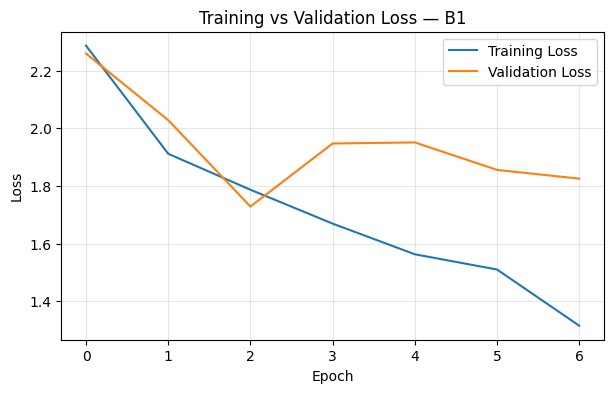

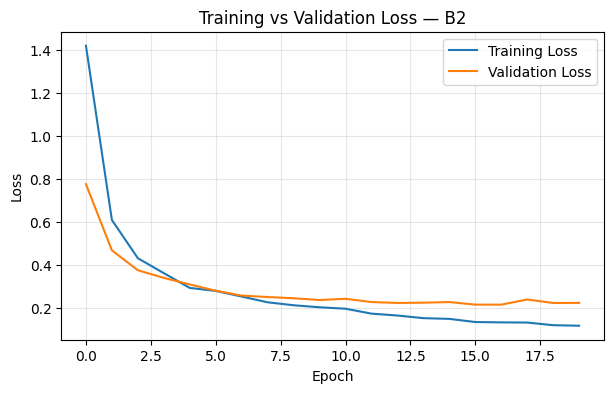

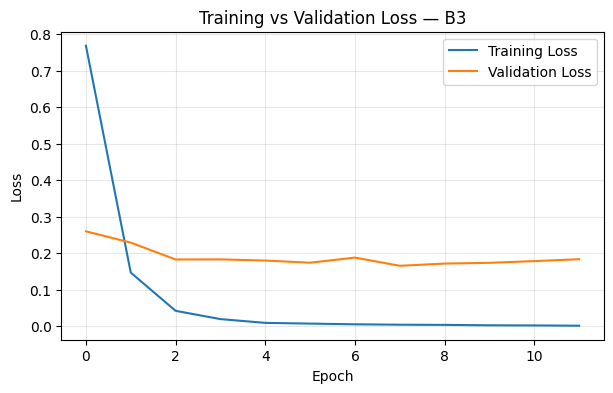

In [63]:
for exp in ["B1", "B2", "B3"]:
    history = histories[exp]

    plt.figure(figsize=(7, 4))
    plt.plot(history["train_loss"], label="Training Loss")
    plt.plot(history["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Training vs Validation Loss — {exp}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

Generalization Gap di B4 (akurasi)

In [64]:
#ukur train accuracy tanpa augmentasi
train_eval_dataset = OxfordPetSubset(
    full_dataset, train_pos, eval_transform, original_to_new
)
train_eval_loader = DataLoader(
    train_eval_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

b4_gap_rows = []

for exp in ["B4_No_Aug", "B4_With_Aug"]:
    model = trained_models[exp]
    _, train_eval_acc, _, _ = evaluate(model, train_eval_loader)
    val_acc = results_df.loc[
        results_df["experiment"] == exp, "val_accuracy_at_best"
    ].iloc[0]

    b4_gap_rows.append({
        "experiment": exp,
        "train_accuracy_eval_transform": train_eval_acc,
        "validation_accuracy_at_best": val_acc,
        "generalization_gap": train_eval_acc - val_acc
    })

b4_gap_df = pd.DataFrame(b4_gap_rows)
display(b4_gap_df.round(4))


,experiment,train_accuracy_eval_transform,validation_accuracy_at_best,generalization_gap
0,B4_No_Aug,1.0000,0.9500,0.0500
1,B4_With_Aug,0.9957,0.9333,0.0624


Menentukan Best Model

In [65]:
selection_df = results_df.copy()

best_row = (
    selection_df
    .sort_values(
        ["val_accuracy_at_best", "best_val_loss"],
        ascending=[False, True]
    )
    .iloc[0]
)

best_experiment = best_row["experiment"]
best_model = trained_models[best_experiment]
best_test = test_outputs[best_experiment]

print("Model terpilih berdasarkan validation metrics:", best_experiment)
print("Validation accuracy:", round(best_row["val_accuracy_at_best"], 4))
print("Best validation loss:", round(best_row["best_val_loss"], 4))
print("Test Accuracy (evaluasi akhir):", round(best_test["test_accuracy"], 4))
print("Test Macro F1 (evaluasi akhir):", round(best_test["test_macro_f1"], 4))


Model terpilih berdasarkan validation metrics: B3
Validation accuracy: 0.95
Best validation loss: 0.1659
Test Accuracy (evaluasi akhir): 0.95
Test Macro F1 (evaluasi akhir): 0.9497


# Failure Analysis

In [ ]:
#test loader untuk model terbaik
_, _, test_dataset_best, _, _, test_loader_best = create_dataloaders(
    train_transform_no_aug
)

@torch.no_grad()
def collect_misclassified(model, loader, max_samples=8):
    model.eval()

    samples = []

    for images, labels in loader:
        images_device = images.to(device)

        outputs = model(images_device)
        probabilities = torch.softmax(outputs, dim=1)

        confidences, predictions = probabilities.max(dim=1)

        for i in range(len(labels)):
            if predictions[i].item() != labels[i].item():
                samples.append({
                    "sample_id": len(samples) + 1,
                    "image": images[i].cpu(),
                    "true_label": labels[i].item(),
                    "predicted_label": predictions[i].item(),
                    "confidence": confidences[i].item()
                })

                if len(samples) >= max_samples:
                    return samples

    return samples


failure_samples = collect_misclassified(
    best_model,
    test_loader_best,
    max_samples=8
)

print("Jumlah sampel misklasifikasi yang ditampilkan:",len(failure_samples))

Jumlah sampel misklasifikasi yang ditampilkan: 8


Visualisasi Failure Analysis

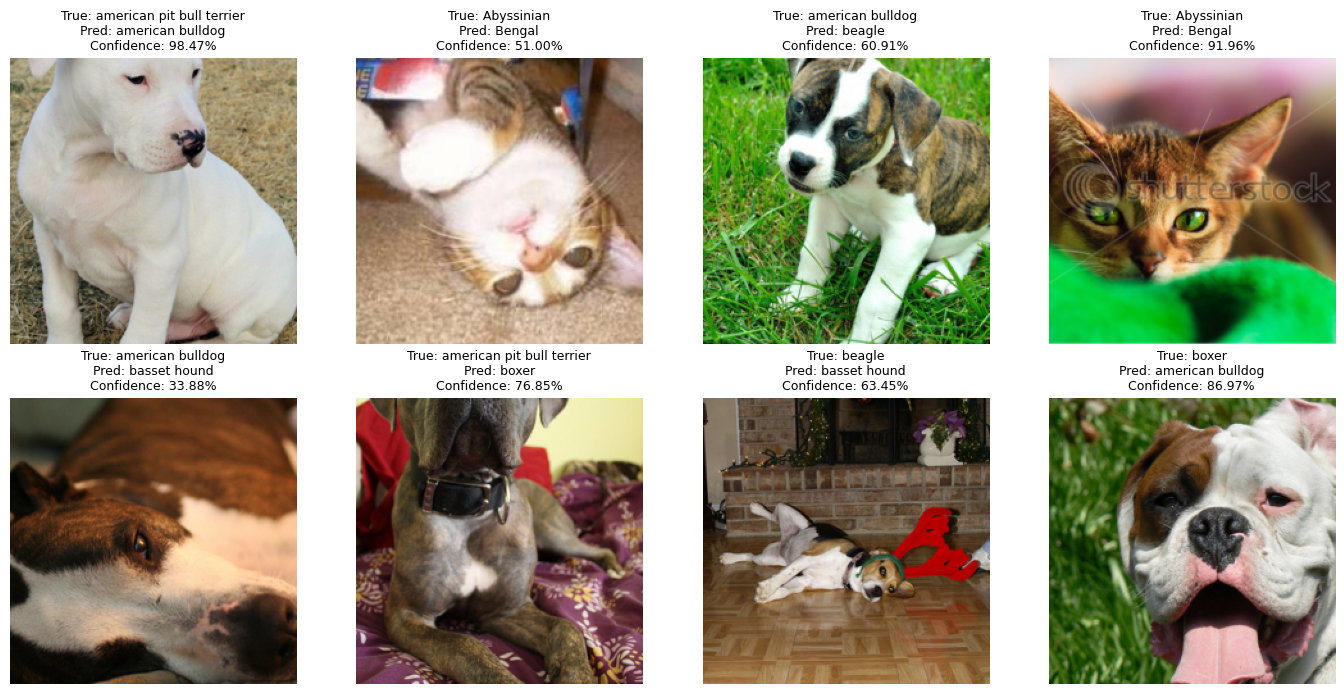

In [67]:
def denormalize(image):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

    image = image * std + mean
    return torch.clamp(image, 0, 1)


fig, axes = plt.subplots(
    2, 4,
    figsize=(14, 7)
)

axes = axes.flatten()

for ax in axes:
    ax.axis("off")

for ax, sample in zip(axes, failure_samples):
    image = denormalize(sample["image"])
    image = image.permute(1, 2, 0).numpy()

    ax.imshow(image)

    true_name = selected_breeds[sample["true_label"]]
    pred_name = selected_breeds[sample["predicted_label"]]

    ax.set_title(
        f"True: {true_name}\n"
        f"Pred: {pred_name}\n"
        f"Confidence: {sample['confidence']:.2%}",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [68]:
failure_analysis_rows = []

for sample in failure_samples:
    failure_analysis_rows.append({
        "sample_id": sample["sample_id"],
        "ground_truth": selected_breeds[sample["true_label"]],
        "prediction": selected_breeds[sample["predicted_label"]],
        "confidence": round(sample["confidence"], 4),
    })

failure_analysis_df = pd.DataFrame(failure_analysis_rows)
display(failure_analysis_df)


,sample_id,ground_truth,prediction,confidence
0,1,american pit bull terrier,american bulldog,0.9847
1,2,Abyssinian,Bengal,0.5100
2,3,american bulldog,beagle,0.6091
3,4,Abyssinian,Bengal,0.9196
4,5,american bulldog,basset hound,0.3388
5,6,american pit bull terrier,boxer,0.7685
6,7,beagle,basset hound,0.6345
7,8,boxer,american bulldog,0.8697


Confusion Matrix Best Model

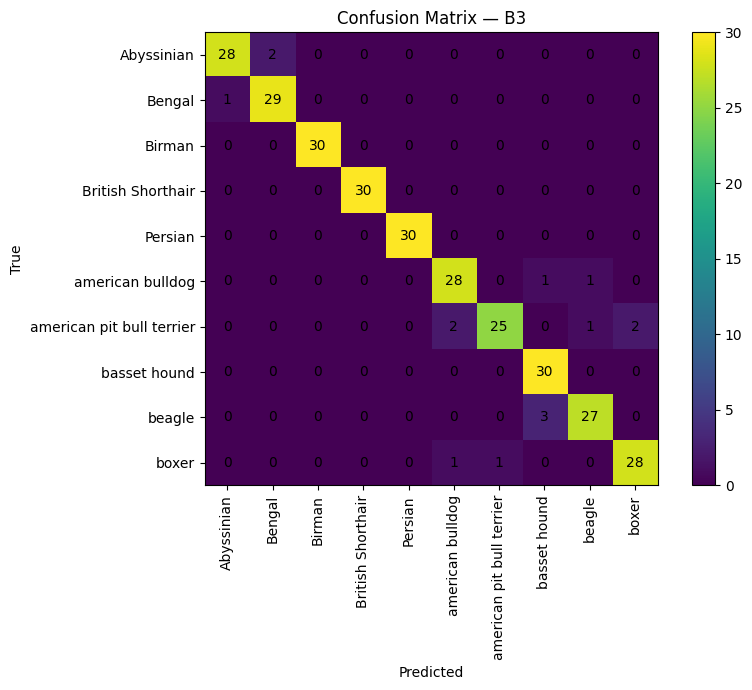

In [69]:
y_true = best_test["y_true"]
y_pred = best_test["y_pred"]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(9, 7))
plt.imshow(cm)
plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    selected_breeds,
    rotation=90
)

plt.yticks(
    range(NUM_CLASSES),
    selected_breeds
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"Confusion Matrix — {best_experiment}")

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

Classification

In [70]:
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=selected_breeds,
        digits=4,
        zero_division=0
    )
)

                           precision    recall  f1-score   support

               Abyssinian     0.9655    0.9333    0.9492        30
                   Bengal     0.9355    0.9667    0.9508        30
                   Birman     1.0000    1.0000    1.0000        30
        British Shorthair     1.0000    1.0000    1.0000        30
                  Persian     1.0000    1.0000    1.0000        30
         american bulldog     0.9032    0.9333    0.9180        30
american pit bull terrier     0.9615    0.8333    0.8929        30
             basset hound     0.8824    1.0000    0.9375        30
                   beagle     0.9310    0.9000    0.9153        30
                    boxer     0.9333    0.9333    0.9333        30

                 accuracy                         0.9500       300
                macro avg     0.9512    0.9500    0.9497       300
             weighted avg     0.9512    0.9500    0.9497       300



Save Experiment

In [71]:
config = {
    "seed": SEED,
    "dataset": "Oxford-IIIT Pet (trainval + official test combined, then internal stratified split)",
    "selected_image_count": int(len(selected_positions)),
    "num_classes": NUM_CLASSES,
    "classes": selected_breeds,
    "split": {
        "train": 0.70,
        "validation": 0.15,
        "test": 0.15
    },
    "input_size": "224x224",
    "batch_size": 32,
    "optimizer": "AdamW",
    "loss": "CrossEntropyLoss",
    "early_stopping_patience": 4,
    "architectures_evaluated": ["ResNet-18", "MobileNetV3-Small"],
    "resnet_pretrained_weights": "ResNet18_Weights.IMAGENET1K_V1",
    "mobilenet_pretrained_weights": "MobileNet_V3_Small_Weights.IMAGENET1K_V1"
}

with open("experiment_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("Done.")

Done.
